# Análisis integral de modelado — Rusty_Baregain_mvp

**Etapa 2.** Este notebook consume los artefactos generados por `analisis_integral_rusty_baregain.ipynb`. Aquí se completa el análisis descriptivo, diagnóstico, evaluación predictiva, comparables y escenarios condicionados. No redefine las reglas de limpieza de la etapa 1.

## Cómo leer este notebook

La **etapa 2** parte de una base ya trazable. El recorrido avanza de hechos observados a estimaciones: primero describe la muestra, luego valida transformaciones, después mide predicciones fuera de muestra y finalmente muestra comparables y escenarios. Un patrón descriptivo no prueba una causa; una predicción no confirma una venta futura.

> El MVP aplica adicionalmente el alcance de vehículos 1991–2016. Este notebook conserva la evidencia integral que permitió justificar esa decisión de producto.


In [10]:
import json
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, mean_absolute_error, root_mean_squared_error
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OrdinalEncoder, RobustScaler

SEED = 42
K_NEIGHBORS = 3
MAX_KNN_DISTANCE = 3.0
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

def project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "processed" / "rusty_baregain_modeling_base.csv").is_file():
            return candidate
    raise FileNotFoundError("Ejecute primero el notebook de etapa 1.")

ROOT = project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
REPORTS_DIR = ROOT / "reports"

## 1. Carga y validación del contrato de artefactos

La etapa 2 falla de forma explícita si no existen los artefactos de etapa 1 o si el lineage no describe el target y la fuente esperados.

In [11]:
lineage = json.loads((REPORTS_DIR / "rusty_baregain_data_lineage.json").read_text(encoding="utf-8"))
assert lineage["target"] == "Price"
assert lineage["target_eligibility"] == "Price > 0; Price no se imputa"
descriptive_data = pd.read_csv(PROCESSED_DIR / "rusty_baregain_descriptive.csv", parse_dates=["DateCrawled", "DateCreated", "LastSeen"])
model_base = pd.read_csv(PROCESSED_DIR / "rusty_baregain_modeling_base.csv", parse_dates=["DateCrawled", "DateCreated", "LastSeen"])
labeled_data = model_base.copy()
print(f"Fuente verificada: {lineage['raw_path']} — SHA-256: {lineage['raw_sha256']}")
print(f"Descriptivo: {len(descriptive_data):,}; base de modelado: {len(model_base):,}")

numeric_features = ["AgeAtCrawl", "PowerForModel", "Mileage"]
categorical_features = ["VehicleType", "Gearbox", "Model", "FuelType", "Brand", "NotRepaired"]
model_features = numeric_features + categorical_features
assert set(model_features + ["Price", "DateCrawled"]).issubset(model_base.columns)

Fuente verificada: data/raw/car_data.csv — SHA-256: fbe6fc8bf597d30c26f810e4768244776b65248b9617069e803b42e9515e10b0
Descriptivo: 354,107; base de modelado: 343,337


### Qué valida este bloque

No basta con que exista un archivo con el nombre esperado. Se comprueba el target, la regla de elegibilidad y las columnas necesarias antes de continuar. Si este contrato falla, los resultados posteriores no deben interpretarse ni reutilizarse.

## 2. Análisis descriptivo profundo

Las métricas de precio usan sólo `model_base` (`Price > 0`). Las observaciones sin precio se mantienen exclusivamente en la etapa 1 para calidad y cobertura. Los resultados describen el periodo y la muestra disponibles; no son efectos causales.

,n,mediana,p25,p75,media
Brand,,,,,
volkswagen,74360,"2,800.00","1,200.00","6,500.00","4,534.41"
opel,38501,"1,600.00",780.00,"3,700.00","2,829.28"
bmw,35776,"4,999.00","2,200.00","9,500.00","6,353.08"
mercedes_benz,31338,"4,449.50","2,000.00","8,750.00","6,039.95"
audi,28557,"4,900.00","1,999.00","9,900.00","6,431.09"
ford,24441,"1,700.00",799.00,"4,100.00","3,268.47"
renault,17377,"1,350.00",750.00,"2,899.00","2,339.87"
peugeot,10771,"2,250.00","1,000.00","4,100.00","3,173.24"
fiat,9323,"1,600.00",750.00,"3,800.00","2,784.31"


n  mediana      p25      p75
Brand         Model                                        
volkswagen    golf         28229 2,500.00 1,199.00 6,099.00
bmw           3er          19162 3,500.00 1,750.00 7,450.00
volkswagen    polo         12619 1,450.00   650.00 3,350.00
opel          corsa        12186 1,099.00   599.00 2,300.00
              astra        10466 1,800.00   899.00 4,199.00
volkswagen    passat        9826 3,200.00 1,500.00 6,500.00
audi          a4            9636 4,500.00 1,900.00 8,950.00
mercedes_benz c_klasse      8169 3,650.00 1,800.00 7,850.00
bmw           5er           7658 5,390.00 2,300.00 9,800.00
mercedes_benz e_klasse      6625 4,500.00 1,950.00 8,400.00
audi          a3            6026 4,990.00 2,150.00 9,200.00
ford          focus         5744 1,999.00 1,000.00 4,500.00
              fiesta        5653 1,499.00   650.00 3,600.00
audi          a6            5364 5,499.00 2,499.00 9,800.00
renault       twingo        4813   950.00   550.00 1,500.00
peugeot       2_reihe       4757 2,499.00 1,300.00 4,200.00
volkswagen    transporter   4685 5,500.00 2,990.00 9,950.00
smart         fortwo        4291 2,980.00 1,790.00 4,990.00
mercedes_benz a_klasse      4131 2,150.00 1,250.00 4,300.00
opel          vectra        4092 1,200.00   650.00 2,350.00

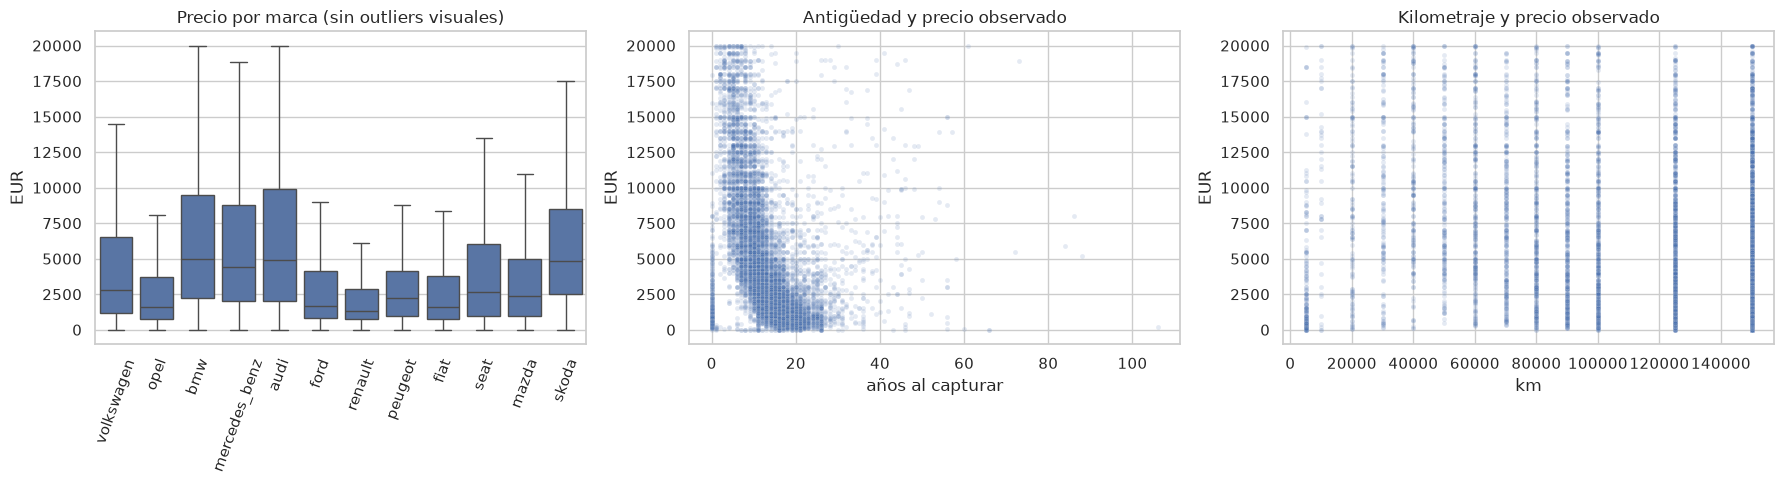

,correlación_Spearman_con_Price
AgeAtCrawl,-0.63
Mileage,-0.33
PowerForModel,0.52
Price,1.00


In [12]:
# Distribución y heterogeneidad de precio por las dimensiones disponibles.
price_by_brand = (model_base.groupby("Brand", dropna=False)["Price"].agg(n="size", mediana="median", p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75), media="mean")
                  .query("n >= 100").sort_values("n", ascending=False))
price_by_model = (model_base.groupby(["Brand", "Model"], dropna=False)["Price"].agg(n="size", mediana="median", p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75))
                  .query("n >= 30").sort_values("n", ascending=False))
display(price_by_brand.head(15))
display(price_by_model.head(20))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_brands = price_by_brand.head(12).index
sns.boxplot(data=model_base[model_base["Brand"].isin(top_brands)], x="Brand", y="Price", order=top_brands, showfliers=False, ax=axes[0])
axes[0].tick_params(axis="x", rotation=70); axes[0].set(title="Precio por marca (sin outliers visuales)", xlabel="", ylabel="EUR")
sns.scatterplot(data=model_base.sample(min(12_000, len(model_base)), random_state=SEED), x="AgeAtCrawl", y="Price", alpha=.15, s=12, ax=axes[1])
axes[1].set(title="Antigüedad y precio observado", xlabel="años al capturar", ylabel="EUR")
sns.scatterplot(data=model_base.sample(min(12_000, len(model_base)), random_state=SEED), x="Mileage", y="Price", alpha=.15, s=12, ax=axes[2])
axes[2].set(title="Kilometraje y precio observado", xlabel="km", ylabel="EUR")
plt.tight_layout(); plt.show()

spearman = model_base[["Price", "AgeAtCrawl", "PowerForModel", "Mileage"]].corr(method="spearman")["Price"].sort_values().to_frame("correlación_Spearman_con_Price")
display(spearman)


### Cómo leer estos gráficos

Las medianas por marca o modelo resumen grupos heterogéneos: no implican que una marca “cause” un precio mayor. Las correlaciones de Spearman muestran asociación monotónica en esta muestra; ayudan a formular preguntas, pero no sustituyen una comparación de vehículos realmente equivalentes.

## 3. Tiempo, tamaño de grupos y cobertura analítica

Se separa la fecha de captura de la antigüedad del vehículo. Con sólo marzo–abril de 2016, cualquier patrón temporal es descriptivo y no permite estimar inflación ni tendencia de mercado de largo plazo.

,grupos_brand_model,grupos_con_1_registro_%,grupos_con_menos_de_10_%,registros_en_grupos_10_mas_%
0,337,0.59,2.97,99.99


,registros_por_brand_model
count,337.00
mean,"1,018.80"
std,"2,487.20"
min,1.00
25%,117.00
50%,315.00
75%,846.00
90%,"2,108.60"
95%,"4,369.80"
99%,"11,566.80"


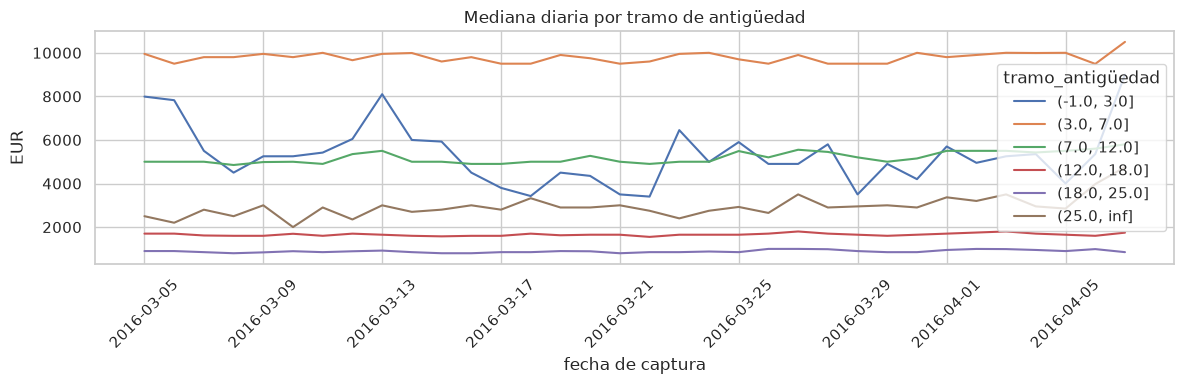

In [13]:
temporal = (model_base.assign(día=model_base["DateCrawled"].dt.normalize(), tramo_antigüedad=pd.cut(model_base["AgeAtCrawl"], [-1, 3, 7, 12, 18, 25, np.inf]))
            .groupby(["día", "tramo_antigüedad"], observed=True)["Price"].median().reset_index())
group_sizes = (model_base.groupby(["Brand", "Model"], dropna=False).size().rename("n").reset_index())
group_coverage = pd.DataFrame({
    "grupos_brand_model": [len(group_sizes)],
    "grupos_con_1_registro_%": [100 * group_sizes["n"].eq(1).mean()],
    "grupos_con_menos_de_10_%": [100 * group_sizes["n"].lt(10).mean()],
    "registros_en_grupos_10_mas_%": [100 * group_sizes.loc[group_sizes["n"].ge(10), "n"].sum() / len(model_base)],
})
display(group_coverage)
display(group_sizes["n"].describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame("registros_por_brand_model"))
fig, ax = plt.subplots(figsize=(12,4))
sns.lineplot(data=temporal, x="día", y="Price", hue="tramo_antigüedad", estimator=None, ax=ax)
ax.set(title="Mediana diaria por tramo de antigüedad", ylabel="EUR", xlabel="fecha de captura")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


### Por qué importa el tamaño de grupo

Un grupo `Brand + Model` grande ofrece más contexto para comparables e imputación. Los grupos pequeños no se eliminan automáticamente, pero requieren más cautela: una mediana calculada con pocos registros puede cambiar mucho con una sola observación adicional.

## 4. Partición temporal

La prueba representa perfiles capturados después de los de entrenamiento. Ningún imputador, escalador, codificador ni modelo aprende de la prueba.

In [14]:
days = np.sort(model_base["DateCrawled"].dt.normalize().unique())
cutoff = days[int(len(days) * 0.8)]
train_raw = model_base.loc[model_base["DateCrawled"].dt.normalize() < cutoff].copy()
test_raw = model_base.loc[model_base["DateCrawled"].dt.normalize() >= cutoff].copy()
y_train, y_test = train_raw["Price"].copy(), test_raw["Price"].copy()
print(f"Entrenamiento: {train_raw['DateCrawled'].min().date()} a {train_raw['DateCrawled'].max().date()} — {len(train_raw):,} filas")
print(f"Prueba: {test_raw['DateCrawled'].min().date()} a {test_raw['DateCrawled'].max().date()} — {len(test_raw):,} filas")

Entrenamiento: 2016-03-05 a 2016-03-31 — 287,578 filas
Prueba: 2016-04-01 a 2016-04-07 — 55,759 filas


### Qué protege esta partición

El test representa los últimos días disponibles. Al mantenerlo aislado hasta la evaluación, el error reportado se parece más a la situación de estimar un perfil que todavía no se había observado en el historial. Esto no convierte un periodo de 2016 en una prueba del mercado actual.

## 5. Imputación por grupo: implementación sin fuga

La alternativa KNN sólo utiliza donantes del entrenamiento y se limita a la misma combinación de categorías de agrupación. Para variables discretas se elige un valor observado ponderado; para categóricas se usa una categoría donante ponderada. Si no hay tres vecinos válidos o están demasiado lejos, no se fuerza la imputación: las categorías pasan a `unknown` y los numéricos restantes reciben el fallback explícito del preprocesador.

In [15]:
group_columns = ["Brand", "Model"]
imputation_fields = ["PowerForModel", "VehicleType", "Gearbox", "FuelType", "NotRepaired"]

def _weighted_mode(values, distances):
    weights = 1 / (distances + 1e-6)
    same = values[:, :, None] == values[:, None, :]
    scores = (same * weights[:, None, :]).sum(axis=2)
    return values[np.arange(len(values)), scores.argmax(axis=1)]

def _neighbors(donors, targets, predictors):
    if len(donors) < K_NEIGHBORS or len(targets) == 0:
        return None, None
    scaler = RobustScaler()
    donor_matrix = scaler.fit_transform(donors[predictors].astype(float))
    target_matrix = scaler.transform(targets[predictors].astype(float))
    return NearestNeighbors(n_neighbors=K_NEIGHBORS).fit(donor_matrix).kneighbors(target_matrix)

def group_knn_transform(frame, donor_source):
    result = frame.copy()
    for field in imputation_fields:
        invalid = result[field].isna() if field != "PowerForModel" else result[field].isna() | result[field].le(0)
        result[f"{field}_faltante_original"] = invalid.astype("int8")
        result[f"{field}_imputado_knn"] = 0
    # En muestras de validación una columna categórica puede quedar enteramente
    # vacía; forzamos object antes de escribir etiquetas categóricas.
    for field in ["VehicleType", "Gearbox", "FuelType", "NotRepaired"]:
        result[field] = result[field].astype("object")

    donor_groups = {key: group.copy() for key, group in donor_source.groupby(group_columns, dropna=False, sort=False)}
    eligible_groups = result.loc[result[group_columns].notna().all(axis=1)].groupby(group_columns, sort=False).groups

    # Potencia: variable discreta; se elige un valor existente, no un promedio.
    for key, idx in eligible_groups.items():
        target_group = result.loc[idx]
        donors = donor_groups.get(key)
        if donors is None:
            continue
        predictors = ["AgeAtCrawl", "Mileage"]
        donor_mask = donors["PowerForModel"].notna() & donors[predictors].notna().all(axis=1)
        target_mask = (target_group["PowerForModel"].isna() | target_group["PowerForModel"].le(0)) & target_group[predictors].notna().all(axis=1)
        donor_rows, target_rows = donors.loc[donor_mask], target_group.loc[target_mask]
        distances, positions = _neighbors(donor_rows, target_rows, predictors)
        if distances is None:
            continue
        accepted = distances.mean(axis=1) <= MAX_KNN_DISTANCE
        values = donor_rows["PowerForModel"].to_numpy(dtype=float)[positions]
        imputed = _weighted_mode(values, distances)
        accepted_index = target_rows.index[accepted]
        result.loc[accepted_index, "PowerForModel"] = imputed[accepted]
        result.loc[accepted_index, "PowerForModel_imputado_knn"] = 1

    # Categóricas: se elige categoría observada entre vecinos del mismo grupo.
    for field in ["VehicleType", "Gearbox", "FuelType", "NotRepaired"]:
        for key, idx in eligible_groups.items():
            target_group = result.loc[idx]
            donors = donor_groups.get(key)
            if donors is None:
                continue
            predictors = numeric_features
            donor_mask = donors[field].notna() & donors[predictors].notna().all(axis=1)
            target_mask = target_group[field].isna() & target_group[predictors].notna().all(axis=1)
            donor_rows, target_rows = donors.loc[donor_mask], target_group.loc[target_mask]
            distances, positions = _neighbors(donor_rows, target_rows, predictors)
            if distances is None:
                continue
            accepted = distances.mean(axis=1) <= MAX_KNN_DISTANCE
            values = donor_rows[field].astype(str).to_numpy()[positions]
            imputed = _weighted_mode(values, distances)
            accepted_index = target_rows.index[accepted]
            result.loc[accepted_index, field] = imputed[accepted]
            result.loc[accepted_index, f"{field}_imputado_knn"] = 1

    result["Model_faltante_original"] = result["Model"].isna().astype("int8")
    result["Model"] = result["Model"].fillna("unknown_model")
    for field in ["VehicleType", "Gearbox", "FuelType", "NotRepaired"]:
        result[field] = result[field].fillna("unknown")
    return result

train_knn = group_knn_transform(train_raw, train_raw)
test_knn = group_knn_transform(test_raw, train_raw)
imputation_report = pd.DataFrame({
    "campo": imputation_fields,
    "imputados_train": [int(train_knn[f"{field}_imputado_knn"].sum()) for field in imputation_fields],
    "imputados_test": [int(test_knn[f"{field}_imputado_knn"].sum()) for field in imputation_fields],
    "unknown_train": [int((train_knn[field] == "unknown").sum()) if field != "PowerForModel" else int(train_knn[field].isna().sum()) for field in imputation_fields],
    "unknown_test": [int((test_knn[field] == "unknown").sum()) if field != "PowerForModel" else int(test_knn[field].isna().sum()) for field in imputation_fields],
})
display(imputation_report)

,campo,imputados_train,imputados_test,unknown_train,unknown_test
0,PowerForModel,24077,4438,6846,1279
1,VehicleType,13260,2406,15182,2897
2,Gearbox,10780,1945,3898,730
3,FuelType,16062,2966,8808,1619
4,NotRepaired,44410,8353,10978,2117


### Cómo interpretar el reporte de imputación

`imputados_*` cuenta los casos con evidencia local suficiente. `unknown_*` no es un fallo oculto: indica que la regla prefirió conservar incertidumbre antes que inventar una categoría. El modelo recibe además indicadores para saber qué valor era originalmente ausente.

## 6. Validación de imputación por ocultamiento

Se ocultan valores observados de entrenamiento y se intenta recuperarlos usando donantes distintos. La comparación contra mediana/moda es una prueba de utilidad de la regla, no una garantía de causalidad ni de desempeño futuro.

In [16]:
rng = np.random.default_rng(SEED)

def masked_validation(field, n=500):
    valid = train_raw[field].notna().copy()
    if field == "PowerForModel":
        valid &= train_raw[field].gt(0)
    candidates = train_raw.loc[valid]
    sample_index = rng.choice(candidates.index.to_numpy(), size=min(n, len(candidates)), replace=False)
    donors = train_raw.drop(index=sample_index)
    probe = train_raw.loc[sample_index].copy()
    truth = probe[field].copy()
    probe[field] = np.nan
    recovered = group_knn_transform(probe, donors)
    if field == "PowerForModel":
        covered = recovered[field].notna()
        knn_metric = mean_absolute_error(truth.loc[covered], recovered.loc[covered, field]) if covered.any() else np.nan
        baseline_value = donors[field].median()
        baseline_metric = mean_absolute_error(truth, np.full(len(truth), baseline_value))
        metric_name = "MAE"
    else:
        covered = recovered[field].ne("unknown")
        knn_metric = accuracy_score(truth.loc[covered], recovered.loc[covered, field]) if covered.any() else np.nan
        baseline_value = donors[field].mode(dropna=True).iat[0]
        baseline_metric = accuracy_score(truth, np.full(len(truth), baseline_value))
        metric_name = "accuracy"
    return {"campo": field, "métrica": metric_name, "cobertura_KNN_%": 100 * covered.mean(), "KNN": knn_metric, "baseline_mediana_moda": baseline_metric}

imputation_validation = pd.DataFrame([masked_validation("PowerForModel"), masked_validation("Gearbox")])
display(imputation_validation)

,campo,métrica,cobertura_KNN_%,KNN,baseline_mediana_moda
0,PowerForModel,MAE,91.60,22.78,38.49
1,Gearbox,accuracy,94.60,0.85,0.80


### Criterio de aceptación de la imputación

Para potencia, un MAE menor es mejor; para transmisión, una mayor exactitud es mejor. La cobertura informa en qué proporción de valores ocultados hubo vecinos suficientemente comparables. La regla KNN se justifica por esta prueba, no sólo porque complete más celdas.

## 7. Evaluación predictiva base

Ambas alternativas usan la misma separación temporal y el mismo modelo. La baseline completa numéricos con mediana y categóricos con moda del entrenamiento. La alternativa KNN usa primero la regla por grupo y conserva indicadores de ausencia; sólo los casos sin cobertura local reciben el fallback del preprocesador.

In [17]:
def baseline_transform(frame, train_reference):
    result = frame.copy()
    for field in imputation_fields:
        invalid = result[field].isna() if field != "PowerForModel" else result[field].isna() | result[field].le(0)
        result[f"{field}_faltante_original"] = invalid.astype("int8")
        result[f"{field}_imputado_knn"] = 0
    result["Model_faltante_original"] = result["Model"].isna().astype("int8")
    return result

def encode_train_test(train_frame, test_frame):
    flag_features = [f"{field}_faltante_original" for field in imputation_fields] + ["Model_faltante_original"] + [f"{field}_imputado_knn" for field in imputation_fields]
    numeric_imputer = SimpleImputer(strategy="median")
    categorical_imputer = SimpleImputer(strategy="most_frequent")
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    train_num = numeric_imputer.fit_transform(train_frame[numeric_features])
    test_num = numeric_imputer.transform(test_frame[numeric_features])
    train_cat = encoder.fit_transform(categorical_imputer.fit_transform(train_frame[categorical_features]))
    test_cat = encoder.transform(categorical_imputer.transform(test_frame[categorical_features]))
    train_flags = train_frame[flag_features].fillna(0).to_numpy(dtype=float)
    test_flags = test_frame[flag_features].fillna(0).to_numpy(dtype=float)
    names = numeric_features + categorical_features + flag_features
    categorical_mask = np.array([False] * len(numeric_features) + [True] * len(categorical_features) + [False] * len(flag_features))
    return np.hstack([train_num, train_cat, train_flags]), np.hstack([test_num, test_cat, test_flags]), names, categorical_mask

def fit_and_evaluate(name, train_frame, test_frame):
    Xtr, Xte, names, categorical_mask = encode_train_test(train_frame, test_frame)
    model = HistGradientBoostingRegressor(
        learning_rate=0.08, max_iter=120, max_leaf_nodes=31, l2_regularization=1.0,
        early_stopping=True, validation_fraction=0.1, categorical_features=categorical_mask, random_state=SEED,
    )
    started = perf_counter(); model.fit(Xtr, y_train); train_seconds = perf_counter() - started
    prediction = model.predict(Xte)
    return {
        "nombre": name, "model": model, "prediction": prediction, "X_test": Xte,
        "feature_names": names, "MAE_EUR": mean_absolute_error(y_test, prediction),
        "RMSE_EUR": root_mean_squared_error(y_test, prediction), "sesgo_EUR": float(np.mean(prediction - y_test)),
        "entrenamiento_s": train_seconds,
    }

train_baseline = baseline_transform(train_raw, train_raw)
test_baseline = baseline_transform(test_raw, train_raw)
baseline_result = fit_and_evaluate("mediana/moda + indicadores", train_baseline, test_baseline)
knn_result = fit_and_evaluate("KNN por grupo + unknown + indicadores", train_knn, test_knn)
median_prediction = np.full(len(y_test), y_train.median())

model_comparison = pd.DataFrame([
    {"método": "mediana de Price en entrenamiento", "MAE_EUR": mean_absolute_error(y_test, median_prediction), "RMSE_EUR": root_mean_squared_error(y_test, median_prediction), "sesgo_EUR": float(np.mean(median_prediction-y_test)), "entrenamiento_s": 0.0},
    {key: value for key, value in baseline_result.items() if key in ["nombre", "MAE_EUR", "RMSE_EUR", "sesgo_EUR", "entrenamiento_s"]} | {"método": baseline_result["nombre"]},
    {key: value for key, value in knn_result.items() if key in ["nombre", "MAE_EUR", "RMSE_EUR", "sesgo_EUR", "entrenamiento_s"]} | {"método": knn_result["nombre"]},
]).drop(columns=["nombre"], errors="ignore").sort_values("MAE_EUR")
display(model_comparison)

selected_result = knn_result if knn_result["MAE_EUR"] <= baseline_result["MAE_EUR"] else baseline_result
selected_train = train_knn if selected_result is knn_result else train_baseline
selected_test = test_knn if selected_result is knn_result else test_baseline
print(f"Pipeline seleccionado por MAE temporal: {selected_result['nombre']}")

,método,MAE_EUR,RMSE_EUR,sesgo_EUR,entrenamiento_s
2,KNN por grupo + unknown + indicadores,"1,065.74","1,702.10",-112.37,1.03
1,mediana/moda + indicadores,"1,067.62","1,709.86",-113.42,1.02
0,mediana de Price en entrenamiento,"3,366.42","4,973.11","-1,881.88",0.00


Pipeline seleccionado por MAE temporal: KNN por grupo + unknown + indicadores


### Cómo leer las métricas del modelo

El MAE se expresa en EUR: es la distancia absoluta media entre la estimación y el precio observado en la prueba histórica. RMSE penaliza más los errores grandes y el sesgo revela si el modelo tiende a sobre- o subestimar. La baseline de mediana permite comprobar que el modelo añade valor real frente a una referencia simple.

## 8. Error e importancia predictiva

La importancia por permutación mide cuánto empeora el MAE al perturbar una variable ya preparada. No es causalidad y no se usa por sí sola para eliminar variables.

In [18]:
test_results = selected_test[["Brand", "Model", "VehicleType", "Gearbox", "FuelType", "NotRepaired", "AgeAtCrawl", "PowerForModel", "Mileage"]].copy()
test_results["Price"] = y_test
test_results["prediction"] = selected_result["prediction"]
test_results["absolute_error"] = (test_results["Price"] - test_results["prediction"]).abs()
test_results["PriceBand"] = pd.cut(test_results["Price"], [0, 1_000, 5_000, 10_000, np.inf], include_lowest=True)
segment_error = (test_results.groupby("PriceBand", observed=True)
                 .agg(n=("Price", "size"), MAE_EUR=("absolute_error", "mean"), sesgo_EUR=("prediction", lambda value: float((value - test_results.loc[value.index, "Price"]).mean())))
                 .reset_index())
display(segment_error)

sample_size = min(1_500, len(y_test))
sample_positions = np.random.default_rng(SEED).choice(len(y_test), size=sample_size, replace=False)
importance = permutation_importance(selected_result["model"], selected_result["X_test"][sample_positions], y_test.iloc[sample_positions], scoring="neg_mean_absolute_error", n_repeats=1, random_state=SEED)
importance_table = pd.DataFrame({"feature": selected_result["feature_names"], "incremento_MAE_perm": importance.importances_mean}).sort_values("incremento_MAE_perm", ascending=False)
display(importance_table.head(15))

,PriceBand,n,MAE_EUR,sesgo_EUR
0,"(-0.001, 1000.0]",11759,609.36,534.90
1,"(1000.0, 5000.0]",25239,778.79,131.76
2,"(5000.0, 10000.0]",11313,"1,400.26",-291.60
3,"(10000.0, inf]",7448,"2,250.52","-1,689.32"


,feature,incremento_MAE_perm
0,AgeAtCrawl,"1,811.36"
1,PowerForModel,771.24
5,Model,562.27
2,Mileage,372.45
3,VehicleType,107.13
8,NotRepaired,102.47
10,VehicleType_faltante_original,85.93
7,Brand,66.17
6,FuelType,25.89
9,PowerForModel_faltante_original,25.19


### Diagnóstico antes de usar la predicción

Los segmentos con MAE alto merecen una advertencia visible en el MVP. La importancia por permutación responde “qué información ayuda a este modelo”; no responde “qué característica determina el precio” ni permite justificar una acción comercial.

## 9. Referencia histórica de comparables

Los comparables usan sólo ventas observadas del entrenamiento. Primero se exige igualdad exacta de identidad y atributos numéricos; luego se permiten bandas. Se requiere al menos 10 comparables. Sin cobertura se muestra sólo la predicción, con confianza baja, sin inventar un rango monetario global.

In [19]:
def add_bands(frame):
    result = frame.copy()
    result["AgeBand"] = pd.cut(result["AgeAtCrawl"], [-1, 3, 7, 12, 18, 25, np.inf], include_lowest=True).astype(str)
    result["MileageBand"] = pd.cut(result["Mileage"], [0, 50_000, 100_000, 125_000, 150_000, np.inf], include_lowest=True).astype(str)
    result["PowerBand"] = pd.cut(result["PowerForModel"], [0, 60, 90, 120, 160, 220, np.inf], include_lowest=True).astype(str)
    return result

history = add_bands(selected_train.assign(Price=y_train))
candidates = add_bands(selected_test.assign(Price=y_test))
identity = ["Brand", "Model", "VehicleType", "Gearbox", "FuelType", "NotRepaired"]

def reference_table(keys):
    return history.dropna(subset=keys).groupby(keys, dropna=False)["Price"].agg(n="size", p25=lambda x: x.quantile(.25), mediana="median", p75=lambda x: x.quantile(.75)).reset_index()

exact_keys = identity + ["AgeAtCrawl", "Mileage", "PowerForModel"]
relaxed_keys = identity + ["AgeBand", "MileageBand", "PowerBand"]
exact = candidates.merge(reference_table(exact_keys), on=exact_keys, how="left")
relaxed = candidates.merge(reference_table(relaxed_keys), on=relaxed_keys, how="left", suffixes=("", "_relajada"))
use_exact = exact["n"].ge(10)
use_relaxed = ~use_exact & relaxed["n"].ge(10)
reference_price = np.where(use_exact, exact["mediana"], np.where(use_relaxed, relaxed["mediana"], np.nan))
reference_level = np.select([use_exact, use_relaxed], ["exacta", "bandas"], default="sin cobertura")
comparable_results = pd.DataFrame({"Price": y_test, "referencia": reference_price, "nivel": reference_level})
covered = comparable_results["referencia"].notna()
comparable_summary = pd.DataFrame([{
    "cobertura_%": 100 * covered.mean(),
    "MAE_referencia_EUR": mean_absolute_error(comparable_results.loc[covered, "Price"], comparable_results.loc[covered, "referencia"]) if covered.any() else np.nan,
    "exacta_%": 100 * (reference_level == "exacta").mean(),
    "bandas_%": 100 * (reference_level == "bandas").mean(),
    "sin_cobertura_%": 100 * (reference_level == "sin cobertura").mean(),
}])
display(comparable_summary)

,cobertura_%,MAE_referencia_EUR,exacta_%,bandas_%,sin_cobertura_%
0,64.48,"1,014.35",30.09,34.39,35.52


### Qué significa cobertura

La cobertura no es precisión garantizada. Indica cuántos perfiles encuentran suficientes vehículos similares en el historial de entrenamiento. Cuando no hay cobertura, mostrar un rango global sería más decorativo que útil; por eso se conserva sólo la estimación con advertencia de evidencia baja.

## 10. Escenarios condicionados y conclusión

Los escenarios muestran asociaciones del modelo: no prueban que modificar una característica cause una variación de precio. La decisión de adopción del pipeline se toma por evaluación temporal, no por apariencia de valores imputados.

In [20]:
scenario = {}
for field in numeric_features:
    scenario[field] = selected_train[field].median()
for field in categorical_features:
    scenario[field] = selected_train[field].mode(dropna=True).iat[0]
for field in imputation_fields:
    scenario[f"{field}_faltante_original"] = 0
    scenario[f"{field}_imputado_knn"] = 0
scenario["Model_faltante_original"] = 0
scenario = pd.DataFrame([scenario, scenario])
scenario.loc[0, "NotRepaired"] = "yes"
scenario.loc[1, "NotRepaired"] = "no"
_, scenario_matrix, _, _ = encode_train_test(selected_train, scenario)
scenario_prediction = selected_result["model"].predict(scenario_matrix)
scenario_output = scenario[["NotRepaired"]].copy()
scenario_output["precio_estimado_EUR"] = scenario_prediction
display(scenario_output)

display(Markdown(f'''
### Conclusiones operativas

- La fuente contiene **{len(descriptive_data):,}** registros deduplicados; **{len(labeled_data):,}** tienen precio observado positivo y pueden usarse como target.
- El pipeline seleccionado por MAE temporal fue **{selected_result['nombre']}** con MAE de **EUR {selected_result['MAE_EUR']:,.2f}**.
- La referencia de comparables tiene cobertura limitada; cuando no existe cobertura, el MVP debe mostrar una estimación aproximada y advertencia de confianza baja.
- La data cubre un periodo breve de 2016. No se debe presentar la salida como tasación actual ni como recomendación causal.
'''))

,NotRepaired,precio_estimado_EUR
0,yes,"2,387.37"
1,no,"3,377.59"



### Conclusiones operativas

- La fuente contiene **354,107** registros deduplicados; **343,337** tienen precio observado positivo y pueden usarse como target.
- El pipeline seleccionado por MAE temporal fue **KNN por grupo + unknown + indicadores** con MAE de **EUR 1,065.74**.
- La referencia de comparables tiene cobertura limitada; cuando no existe cobertura, el MVP debe mostrar una estimación aproximada y advertencia de confianza baja.
- La data cubre un periodo breve de 2016. No se debe presentar la salida como tasación actual ni como recomendación causal.


## 11. Diagnóstico de error e incertidumbre

El intervalo es empírico: usa el percentil 90 de los residuos absolutos de una ventana temporal interna de calibración. No es un intervalo causal ni una garantía individual; su cobertura debe recalibrarse con nuevos periodos.

In [21]:
test_results["residuo"] = test_results["prediction"] - test_results["Price"]
test_results["AgeBand"] = pd.cut(test_results["AgeAtCrawl"], [-1, 3, 7, 12, 18, 25, np.inf])
test_results["MileageBand"] = pd.cut(test_results["Mileage"], [0, 50_000, 100_000, 125_000, 150_000, np.inf])
diagnostic_dimensions = ["Brand", "VehicleType", "Gearbox", "FuelType", "NotRepaired", "AgeBand", "MileageBand"]
error_diagnostics = []
for field in diagnostic_dimensions:
    table = (test_results.groupby(field, dropna=False).agg(n=("Price", "size"), MAE_EUR=("absolute_error", "mean"), sesgo_EUR=("residuo", "mean"))
             .query("n >= 100").reset_index())
    table["segmento"] = field
    table = table.rename(columns={field: "valor"})
    error_diagnostics.append(table[["segmento", "valor", "n", "MAE_EUR", "sesgo_EUR"]])
error_diagnostics = pd.concat(error_diagnostics, ignore_index=True).sort_values("MAE_EUR", ascending=False)
display(error_diagnostics.head(30))

# Calibración temporal interna: los últimos días del entrenamiento se reservan
# para estimar la amplitud del intervalo; el test no participa en ese ajuste.
calibration_cutoff = np.sort(train_raw["DateCrawled"].dt.normalize().unique())[-3]
dev_raw = train_raw.loc[train_raw["DateCrawled"].dt.normalize() < calibration_cutoff].copy()
cal_raw = train_raw.loc[train_raw["DateCrawled"].dt.normalize() >= calibration_cutoff].copy()
dev_knn = group_knn_transform(dev_raw, dev_raw)
cal_knn = group_knn_transform(cal_raw, dev_raw)
X_dev, X_cal, _, cal_mask = encode_train_test(dev_knn, cal_knn)
interval_model = HistGradientBoostingRegressor(
    learning_rate=0.08, max_iter=120, max_leaf_nodes=31, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.1, categorical_features=cal_mask, random_state=SEED,
).fit(X_dev, dev_raw["Price"])
cal_abs_residual = np.abs(interval_model.predict(X_cal) - cal_raw["Price"].to_numpy())
q90_abs_error = float(np.quantile(cal_abs_residual, .90))
test_results["intervalo_inferior"] = np.maximum(0, test_results["prediction"] - q90_abs_error)
test_results["intervalo_superior"] = test_results["prediction"] + q90_abs_error
interval_coverage = ((test_results["Price"] >= test_results["intervalo_inferior"]) & (test_results["Price"] <= test_results["intervalo_superior"])).mean()
display(pd.DataFrame([{"semi_ancho_intervalo_empírico_EUR": q90_abs_error, "cobertura_test_%": 100*interval_coverage, "objetivo_nominal_%": 90.0, "filas_calibración": len(cal_raw)}]))


,segmento,valor,n,MAE_EUR,sesgo_EUR
21,Brand,porsche,118,"2,820.09",-562.24
26,Brand,sonstige_autos,486,"2,430.50",36.60
56,AgeBand,"(25.0, inf]",1804,"2,207.37",-133.76
12,Brand,jeep,111,"2,053.03",93.17
38,VehicleType,suv,1879,"1,823.64",-183.61
58,MileageBand,"(0.0, 50000.0]",4209,"1,653.52",-180.41
3,Brand,chevrolet,295,"1,633.92",119.24
57,AgeBand,NaN,2249,"1,617.55",-28.98
51,AgeBand,"(-1.0, 3.0]",2773,"1,607.68",-108.00
39,VehicleType,unknown,2897,"1,583.84",49.76


,semi_ancho_intervalo_empírico_EUR,cobertura_test_%,objetivo_nominal_%,filas_calibración
0,"2,461.48",89.61,90.00,34091


### Lectura del intervalo

El semi-ancho se aprendió en una ventana de calibración anterior al test; el test sólo verifica cuántos precios observados quedaron dentro. Por eso la cobertura cercana al 90% es una propiedad empírica de esta fuente histórica, no una promesa individual ni una garantía para datos posteriores.

## 12. Evidencia de comparables y política de confianza

La confianza se basa en evidencia observable: cobertura de comparables, tamaño de grupo y amplitud de rango histórico. No debe confundirse con certeza de la predicción.

In [22]:
comparable_evidence = pd.DataFrame({
    "nivel": reference_level,
    "n_comparables": np.where(use_exact, exact["n"], np.where(use_relaxed, relaxed["n"], np.nan)),
    "p25": np.where(use_exact, exact["p25"], np.where(use_relaxed, relaxed["p25"], np.nan)),
    "mediana": reference_price,
    "p75": np.where(use_exact, exact["p75"], np.where(use_relaxed, relaxed["p75"], np.nan)),
})
comparable_evidence["amplitud_iqr"] = comparable_evidence["p75"] - comparable_evidence["p25"]
comparable_evidence["confianza_evidencia"] = np.select([
    comparable_evidence["nivel"].eq("exacta") & comparable_evidence["n_comparables"].ge(20),
    comparable_evidence["nivel"].ne("sin cobertura")
], ["alta", "media"], default="baja")
evidence_summary = (comparable_evidence.groupby(["nivel", "confianza_evidencia"], dropna=False)
                    .agg(perfiles=("nivel", "size"), n_mediano=("n_comparables", "median"), iqr_mediano_EUR=("amplitud_iqr", "median")).reset_index())
display(evidence_summary)
print("Regla de uso: alta/media = mostrar mediana y rango histórico; baja = mostrar sólo estimación aproximada, límites y advertencia de evidencia insuficiente.")


,nivel,confianza_evidencia,perfiles,n_mediano,iqr_mediano_EUR
0,bandas,media,19174,32.00,"1,324.50"
1,exacta,alta,11140,46.00,779.00
2,exacta,media,5638,14.00,912.25
3,sin cobertura,baja,19807,NaN,NaN


Regla de uso: alta/media = mostrar mediana y rango histórico; baja = mostrar sólo estimación aproximada, límites y advertencia de evidencia insuficiente.


### Uso para una persona compradora

La confianza se refiere a la evidencia histórica disponible, no a la calidad mecánica del vehículo. Una referencia alta o media puede orientar una comparación; una referencia baja es una señal para pedir más información o una revisión humana, no para automatizar una decisión.

## 13. Escenarios condicionados para la persona compradora

Los escenarios mantienen el perfil de referencia y cambian una condición declarada. Son asociaciones del modelo, no el efecto de reparar, aumentar potencia o recorrer kilómetros.

In [23]:
reference_profile = selected_train[model_features].copy()
reference_profile = reference_profile.loc[[reference_profile.index[0]]].copy()
for field in numeric_features:
    reference_profile[field] = selected_train[field].median()
for field in categorical_features:
    reference_profile[field] = selected_train[field].mode(dropna=True).iat[0]
reference_profile["Model"] = selected_train["Model"].mode(dropna=True).iat[0]
scenarios = pd.concat([reference_profile]*4, ignore_index=True)
scenarios["escenario"] = ["referencia", "sin reparación pendiente", "con reparación pendiente", "menor kilometraje"]
scenarios.loc[1, "NotRepaired"] = "no"
scenarios.loc[2, "NotRepaired"] = "yes"
scenarios.loc[3, "Mileage"] = max(5_000, float(scenarios.loc[0, "Mileage"]) - 50_000)
for field in imputation_fields:
    scenarios[f"{field}_faltante_original"] = 0
    scenarios[f"{field}_imputado_knn"] = 0
scenarios["Model_faltante_original"] = 0
_, scenario_matrix, _, _ = encode_train_test(selected_train, scenarios)
scenarios["precio_estimado_EUR"] = selected_result["model"].predict(scenario_matrix)
scenarios["intervalo_empírico"] = scenarios["precio_estimado_EUR"].map(lambda x: f"EUR {max(0, x-q90_abs_error):,.0f} – {x+q90_abs_error:,.0f}")
display(scenarios[["escenario", "NotRepaired", "Mileage", "precio_estimado_EUR", "intervalo_empírico"]])


,escenario,NotRepaired,Mileage,precio_estimado_EUR,intervalo_empírico
0,referencia,no,"150,000.00","3,377.59","EUR 916 – 5,839"
1,sin reparación pendiente,no,"150,000.00","3,377.59","EUR 916 – 5,839"
2,con reparación pendiente,yes,"150,000.00","2,387.37","EUR 0 – 4,849"
3,menor kilometraje,no,"100,000.00","4,348.54","EUR 1,887 – 6,810"


### Límite de los escenarios

El escenario cambia una entrada y mantiene las demás constantes para explicar el comportamiento del modelo. En el mundo real, reparación, kilometraje, equipamiento y estado del vehículo cambian juntos; por eso estas diferencias son simuladas y condicionadas, no el beneficio esperado de una acción.

## Cierre para lectores y reproducibilidad

Este notebook entrega evidencia histórica, no una tasación vigente. Para repetirlo: ejecute primero la etapa 1, confirme que el hash y el lineage coinciden, y luego ejecute este notebook desde un kernel limpio. Para la aplicación, el pipeline del MVP restringe la consulta a vehículos ordinarios de 1991–2016 y recalibra sus artefactos de consumo por separado.